In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier

In [3]:
df = pd.read_csv("../data/processed/climate_ml_ready.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (7270, 19)


,Temperature_Max,Temperature_Min,Temperature_Avg,Humidity,Rainfall,Wind_Speed (km/h),AQI,Pressure_Avg,Cloud_Cover,Temp_Avg_Lag1,AQI_Lag1,Rainfall_Lag1,Humidity_Lag1,Temp_3Day_Avg,AQI_3Day_Avg,Rainfall_3Day_Total,Month,Date,Next_Day_Risk
0,32.8,21.3,27.0,59.8,0.0,24.1,61,1021.7,23.6,29.8,131.0,5.2,39.1,28.466667,233.000000,10.6,1,2024-01-04,0
1,27.4,15.9,21.6,78.5,0.0,8.6,338,1020.4,26.2,27.0,61.0,0.0,59.8,27.833333,138.333333,10.6,1,2024-01-05,0
2,39.1,32.0,35.5,38.9,0.0,11.0,147,1005.3,90.9,21.6,338.0,0.0,78.5,26.133333,176.666667,5.2,1,2024-01-06,2
3,32.1,17.3,24.7,69.4,0.0,7.7,128,995.6,22.7,35.5,147.0,0.0,38.9,28.033333,182.000000,0.0,1,2024-01-07,0
4,28.0,19.9,24.0,46.2,0.0,19.5,294,1020.7,37.5,24.7,128.0,0.0,69.4,27.266667,204.333333,0.0,1,2024-01-08,3


In [4]:
df = df.sort_values("Date").reset_index(drop=True)

print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

First date: 2024-01-04 00:00:00
Last date: 2025-12-30 00:00:00


In [5]:
split_index = int(len(df) * 0.80)

train_data = df.iloc[:split_index]
test_data = df.iloc[split_index:]

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training records: 5816
Testing records: 1454

Training period:
2024-01-04 00:00:00 to 2025-08-07 00:00:00

Testing period:
2025-08-07 00:00:00 to 2025-12-30 00:00:00


In [6]:
feature_columns = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "AQI",
    "Pressure_Avg",
    "Cloud_Cover",
    "Temp_Avg_Lag1",
    "AQI_Lag1",
    "Rainfall_Lag1",
    "Humidity_Lag1",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Rainfall_3Day_Total",
    "Month"
]

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = train_data["Next_Day_Risk"]
y_test = test_data["Next_Day_Risk"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (5816, 17)
X_test: (1454, 17)


Training random forest

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.5020632737276479

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.76      0.65       828
           1       0.00      0.00      0.00        37
           2       0.30      0.23      0.26       420
           3       0.22      0.01      0.02       169

    accuracy                           0.50      1454
   macro avg       0.27      0.25      0.23      1454
weighted avg       0.43      0.50      0.45      1454



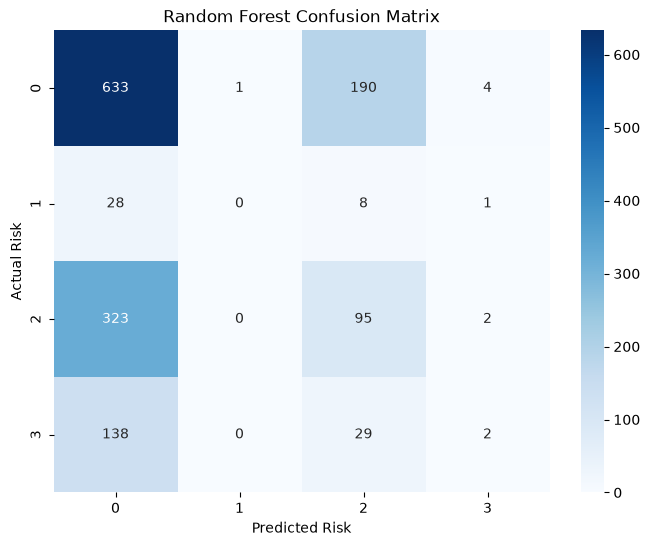

In [8]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.show()

In [9]:
rf_f1 = f1_score(
    y_test,
    rf_predictions,
    average="weighted"
)

print("Random Forest Weighted F1 Score:", round(rf_f1, 4))

Random Forest Weighted F1 Score: 0.4463


In [10]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

XGBoost Accuracy: 0.5522696011004127

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.92      0.70       828
           1       0.00      0.00      0.00        37
           2       0.34      0.10      0.16       420
           3       1.00      0.01      0.02       169

    accuracy                           0.55      1454
   macro avg       0.48      0.26      0.22      1454
weighted avg       0.54      0.55      0.45      1454



d:\OneDrive\Desktop\climate-action-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\OneDrive\Desktop\climate-action-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\OneDrive\Desktop\climate-action-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

In [11]:
xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="weighted"
)

results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    "Weighted F1": [
        rf_f1,
        xgb_f1
    ]
})

results

,Model,Accuracy,Weighted F1
0,Random Forest,0.502063,0.446292
1,XGBoost,0.552270,0.449009


In [12]:
print("XGBoost Classification Report")
print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=["High", "Low", "Moderate", "Severe"],
        zero_division=0
    )
)

XGBoost Classification Report
              precision    recall  f1-score   support

        High       0.57      0.92      0.70       828
         Low       0.00      0.00      0.00        37
    Moderate       0.34      0.10      0.16       420
      Severe       1.00      0.01      0.02       169

    accuracy                           0.55      1454
   macro avg       0.48      0.26      0.22      1454
weighted avg       0.54      0.55      0.45      1454



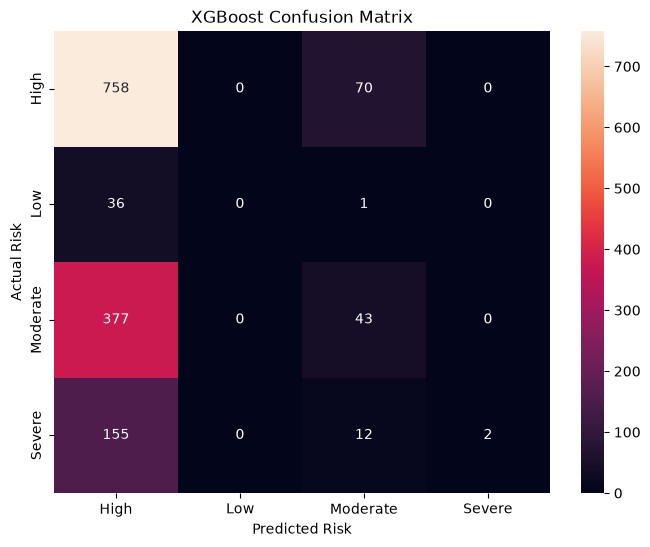

In [13]:
cm = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["High", "Low", "Moderate", "Severe"],
    yticklabels=["High", "Low", "Moderate", "Severe"]
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.show()

In [14]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Class weights calculated successfully.")

Class weights calculated successfully.


In [15]:
xgb_weighted = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

xgb_weighted.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

weighted_predictions = xgb_weighted.predict(X_test)

In [16]:
weighted_accuracy = accuracy_score(
    y_test,
    weighted_predictions
)

weighted_f1 = f1_score(
    y_test,
    weighted_predictions,
    average="weighted"
)

macro_f1 = f1_score(
    y_test,
    weighted_predictions,
    average="macro"
)

print("Weighted XGBoost Accuracy:", round(weighted_accuracy, 4))
print("Weighted XGBoost Weighted F1:", round(weighted_f1, 4))
print("Weighted XGBoost Macro F1:", round(macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        weighted_predictions,
        target_names=["High", "Low", "Moderate", "Severe"],
        zero_division=0
    )
)

Weighted XGBoost Accuracy: 0.4237
Weighted XGBoost Weighted F1: 0.4287
Weighted XGBoost Macro F1: 0.2646

Classification Report:
              precision    recall  f1-score   support

        High       0.59      0.53      0.56       828
         Low       0.04      0.03      0.03        37
    Moderate       0.30      0.35      0.32       420
      Severe       0.14      0.15      0.15       169

    accuracy                           0.42      1454
   macro avg       0.27      0.27      0.26      1454
weighted avg       0.44      0.42      0.43      1454



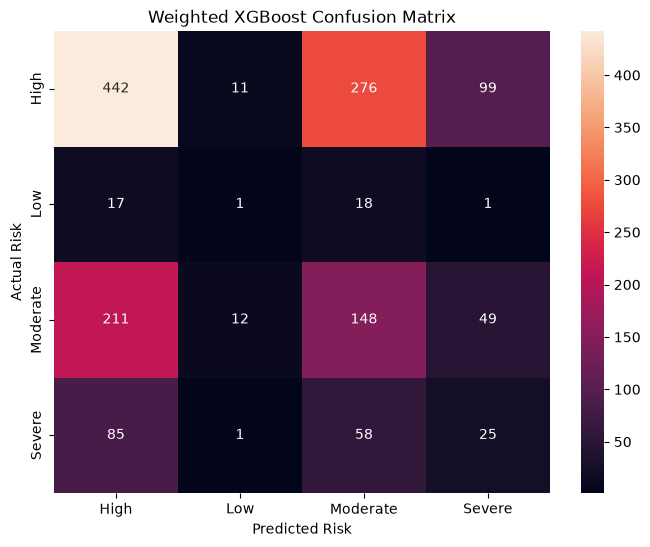

In [17]:
cm = confusion_matrix(y_test, weighted_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["High", "Low", "Moderate", "Severe"],
    yticklabels=["High", "Low", "Moderate", "Severe"]
)

plt.title("Weighted XGBoost Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.show()

In [18]:
xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="weighted"
)

results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    "Weighted F1": [
        rf_f1,
        xgb_f1
    ]
})

results

,Model,Accuracy,Weighted F1
0,Random Forest,0.502063,0.446292
1,XGBoost,0.552270,0.449009


In [19]:
print("Weighted XGBoost Accuracy:", round(weighted_accuracy, 4))
print("Weighted XGBoost Weighted F1:", round(weighted_f1, 4))
print("Weighted XGBoost Macro F1:", round(macro_f1, 4))

Weighted XGBoost Accuracy: 0.4237
Weighted XGBoost Weighted F1: 0.4287
Weighted XGBoost Macro F1: 0.2646


In [20]:
df = pd.read_csv("../data/processed/climate_ml_ready.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)

Dataset shape: (7260, 23)


In [21]:
feature_columns = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "AQI",
    "Pressure_Avg",
    "Cloud_Cover",
    "Temp_Avg_Lag1",
    "AQI_Lag1",
    "Rainfall_Lag1",
    "Humidity_Lag1",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Rainfall_3Day_Total",
    "Climate_Risk_Score",
    "Climate_Risk_Score_Lag1",
    "Climate_Risk_Lag1",
    "Month"
]

In [22]:
split_index = int(len(df) * 0.80)

train_data = df.iloc[:split_index]
test_data = df.iloc[split_index:]

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = train_data["Next_Day_Risk"]
y_test = test_data["Next_Day_Risk"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5808, 20)
Testing: (1452, 20)


In [23]:
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("Improved XGBoost model trained successfully.")

Improved XGBoost model trained successfully.


In [24]:
accuracy = accuracy_score(y_test, xgb_predictions)

weighted_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="weighted"
)

macro_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="macro"
)

print("Accuracy:", round(accuracy, 4))
print("Weighted F1:", round(weighted_f1, 4))
print("Macro F1:", round(macro_f1, 4))

Accuracy: 0.5551
Weighted F1: 0.452
Macro F1: 0.2216


In [25]:
print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=["High", "Low", "Moderate", "Severe"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        High       0.57      0.92      0.71       827
         Low       0.00      0.00      0.00        37
    Moderate       0.37      0.11      0.17       419
      Severe       0.50      0.01      0.01       169

    accuracy                           0.56      1452
   macro avg       0.36      0.26      0.22      1452
weighted avg       0.49      0.56      0.45      1452



In [28]:
original_df = pd.read_csv("../data/processed/climate_processed.csv")

print("AQI Category distribution:")
print(original_df["AQI_Category"].value_counts())

AQI Category distribution:
AQI_Category
Moderate        2385
Poor            2344
Satisfactory    1194
Very Poor       1136
Good             251
Name: count, dtype: int64


In [29]:
aqi_df = pd.read_csv(
    "../data/processed/aqi_prediction_ready.csv"
)

aqi_df["Date"] = pd.to_datetime(aqi_df["Date"])

aqi_df = aqi_df.sort_values(
    "Date"
).reset_index(drop=True)

print("Dataset shape:", aqi_df.shape)

Dataset shape: (7270, 19)


In [30]:
aqi_features = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "Pressure_Avg",
    "Cloud_Cover",
    "AQI_Lag1",
    "AQI_Lag2",
    "AQI_3Day_Avg",
    "Temperature_Lag1",
    "Humidity_Lag1",
    "Rainfall_Lag1",
    "Wind_Lag1",
    "Month"
]

In [31]:
split_index = int(len(aqi_df) * 0.80)

aqi_train = aqi_df.iloc[:split_index]
aqi_test = aqi_df.iloc[split_index:]

X_train = aqi_train[aqi_features]
X_test = aqi_test[aqi_features]

y_train = aqi_train["Next_Day_AQI_Category"]
y_test = aqi_test["Next_Day_AQI_Category"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining period:")
print(aqi_train["Date"].min(), "to", aqi_train["Date"].max())

print("\nTesting period:")
print(aqi_test["Date"].min(), "to", aqi_test["Date"].max())

Training: (5816, 16)
Testing: (1454, 16)

Training period:
2024-01-04 00:00:00 to 2025-08-07 00:00:00

Testing period:
2025-08-07 00:00:00 to 2025-12-30 00:00:00


In [32]:
aqi_xgb = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

aqi_xgb.fit(X_train, y_train)

aqi_predictions = aqi_xgb.predict(X_test)

print("AQI prediction model trained successfully.")

AQI prediction model trained successfully.


In [33]:
aqi_accuracy = accuracy_score(
    y_test,
    aqi_predictions
)

aqi_weighted_f1 = f1_score(
    y_test,
    aqi_predictions,
    average="weighted"
)

aqi_macro_f1 = f1_score(
    y_test,
    aqi_predictions,
    average="macro"
)

print("Accuracy:", round(aqi_accuracy, 4))
print("Weighted F1:", round(aqi_weighted_f1, 4))
print("Macro F1:", round(aqi_macro_f1, 4))

Accuracy: 0.3157
Weighted F1: 0.2707
Macro F1: 0.1822


In [36]:
from sklearn.preprocessing import LabelEncoder

aqi_encoder = LabelEncoder()

aqi_encoder.fit([
    "Good",
    "Moderate",
    "Poor",
    "Satisfactory",
    "Very Poor"
])

print(
    classification_report(
        y_test,
        aqi_predictions,
        target_names=aqi_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.00      0.00      0.00        52
    Moderate       0.33      0.41      0.36       466
        Poor       0.33      0.52      0.41       471
Satisfactory       0.19      0.06      0.09       236
   Very Poor       0.15      0.03      0.06       229

    accuracy                           0.32      1454
   macro avg       0.20      0.20      0.18      1454
weighted avg       0.27      0.32      0.27      1454



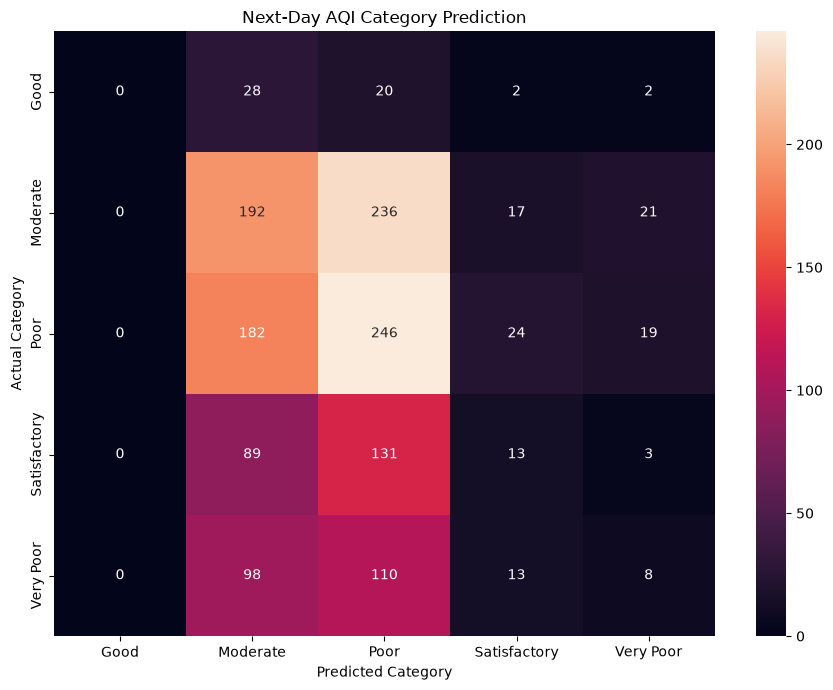

In [37]:
cm = confusion_matrix(
    y_test,
    aqi_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=aqi_encoder.classes_,
    yticklabels=aqi_encoder.classes_
)

plt.title("Next-Day AQI Category Prediction")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [38]:
risk_features = [
    "Temperature_Max",
    "Temperature_Min",
    "Temperature_Avg",
    "Humidity",
    "Rainfall",
    "Wind_Speed (km/h)",
    "AQI",
    "Pressure_Avg",
    "Cloud_Cover",
    "Temp_Avg_Lag1",
    "AQI_Lag1",
    "Rainfall_Lag1",
    "Humidity_Lag1",
    "Temp_3Day_Avg",
    "AQI_3Day_Avg",
    "Rainfall_3Day_Total",
    "Month"
]

X_risk = df[risk_features]
y_risk = df["Next_Day_Risk"]

print("Risk features:", X_risk.shape)
print("Risk target:", y_risk.shape)

Risk features: (7260, 17)
Risk target: (7260,)


In [39]:
split_index = int(len(df) * 0.80)

X_risk_train = X_risk.iloc[:split_index]
X_risk_test = X_risk.iloc[split_index:]

y_risk_train = y_risk.iloc[:split_index]
y_risk_test = y_risk.iloc[split_index:]

print("Training:", X_risk_train.shape)
print("Testing:", X_risk_test.shape)

Training: (5808, 17)
Testing: (1452, 17)


In [40]:
final_model = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42
)

final_model.fit(X_risk_train, y_risk_train)

final_predictions = final_model.predict(X_risk_test)

print("Final Climate Risk model trained successfully.")

Final Climate Risk model trained successfully.


In [41]:
final_accuracy = accuracy_score(
    y_risk_test,
    final_predictions
)

final_f1 = f1_score(
    y_risk_test,
    final_predictions,
    average="weighted"
)

print("Final Accuracy:", round(final_accuracy, 4))
print("Final Weighted F1:", round(final_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_risk_test,
        final_predictions,
        target_names=["High", "Low", "Moderate", "Severe"],
        zero_division=0
    )
)

Final Accuracy: 0.5579
Final Weighted F1: 0.4529

Classification Report:
              precision    recall  f1-score   support

        High       0.57      0.92      0.71       827
         Low       0.00      0.00      0.00        37
    Moderate       0.38      0.11      0.17       419
      Severe       0.50      0.01      0.01       169

    accuracy                           0.56      1452
   macro avg       0.36      0.26      0.22      1452
weighted avg       0.49      0.56      0.45      1452



In [42]:
importance = pd.DataFrame({
    "Feature": risk_features,
    "Importance": final_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

                Feature  Importance
2       Temperature_Avg    0.061343
1       Temperature_Min    0.060403
6                   AQI    0.059708
10             AQI_Lag1    0.059550
8           Cloud_Cover    0.059249
15  Rainfall_3Day_Total    0.059189
14         AQI_3Day_Avg    0.059069
12        Humidity_Lag1    0.059036
13        Temp_3Day_Avg    0.058989
4              Rainfall    0.058898
9         Temp_Avg_Lag1    0.058409
3              Humidity    0.058361
5     Wind_Speed (km/h)    0.057825
11        Rainfall_Lag1    0.057812
0       Temperature_Max    0.057772
16                Month    0.057505
7          Pressure_Avg    0.056884


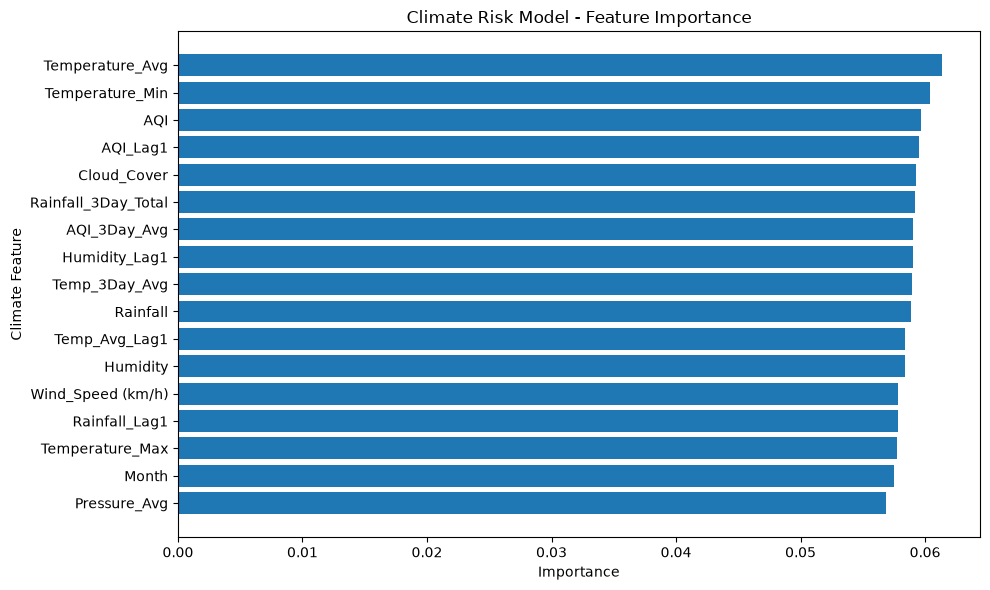

In [43]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Climate Feature")
plt.title("Climate Risk Model - Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [44]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/climate_risk_model.pkl"
)

joblib.dump(
    risk_features,
    "../models/risk_features.pkl"
)

print("Final Climate Risk model saved successfully.")

Final Climate Risk model saved successfully.
